In [1]:
import matplotlib.pyplot as plt
import numpy as np

<h1> Programming for Physics <br> Lecture 17: Simple Iteration and Complex Phenomena </h1>
<a target="_blank" href="https://colab.research.google.com/github/slxuphys/tamu_phys_150/blob/master/2026/lecture-17-iteration.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" style="background-color: white;"/>
</a>

  
   


---

# A Short Summary

## Motion

Simulate the motion by dividing continuous time into discrete steps.

<table style="border-collapse: collapse; border: none;">
<tr>
<td style="border: none; vertical-align: middle; text-align: left; padding: 12px; white-space: normal;">

<img src="../gallery/three_body.gif" alt="image" style="background-color: white;">

</td>
<td style="border: none; vertical-align: middle; text-align: left; padding: 12px; white-space: normal;">

$$
\begin{aligned}
a_ n &= \vec f(\vec r_n, \vec v_n, t) \\
t_{n+1} &= t_{n} + \Delta t \\
\vec v_{n+1} &= \vec v_{n} + a_n \Delta t\\
\vec r_{n+1} &= \vec r_{n} + \vec v_{n+1} \Delta t \\
\end{aligned}
$$

</td>
</tr>
</table>



## Gradient Descend

<table style="border-collapse: collapse; border: none;">
<tr>
<td style="border: none; vertical-align: middle; text-align: left; padding: 12px; white-space: normal;">

<img src='https://i0.wp.com/analyticsarora.com/wp-content/uploads/2022/02/gradient-descent-settles-to-local-optimum-1.png?w=800&ssl=1' height=400 style='height:400px; margin:20px; background-color: white;'>

</td>
<td style="border: none; vertical-align: middle; text-align: left; padding: 12px; white-space: normal;">

$
x_{n+1} = x_{n} - \gamma f'(x_n)
$


The parameter $\gamma$ here is called the learning rate in machine learning language.

</td>
</tr>
</table>




## Newton Method

$$x_{n+1} = x_{n} - \frac{f(x_n)}{f'(x_n)}$$

<img src='https://upload.wikimedia.org/wikipedia/commons/d/db/Julia_set_for_the_rational_function.png' height=400 style='height:400px; margin:20px; background-color: white;'>





## Common structure:

The quantities at step $n+1$ depend on step $n$ according to some simple rules.

$$
\vec S_{n+1} = F(\vec S_n)
$$
While $F$ can be very simple, complex phenomena can __emerge__ from the simple rules.

### The game of life

<img src='https://miro.medium.com/v2/resize:fit:640/format:webp/1*l4Lm4I87vDusPqCqs7l0yw.gif' style="background-color: white;">




__Is there such a simple rule that leads to all the complex phenomena of our universe ?__

The mug of the standard model:

<img src='https://visit.cern/sites/default/files/inline-images/P1055164.JPG' height=500 style='height:500px;margin:20px; background-color: white;'>

This equation neatly sums up our current understanding of fundamental particles and forces. It represents mathematically what we call the Standard Model of particle physics. The top line describes the forces: electricity, magnetism and the strong and weak nuclear forces. The second line describes how these forces act on the fundamental particles of matter, namely quarks and leptons. The last two lines describe the Higgs boson, and the mechanism by which particles acquire their mass.

However the gravity is still missing and cannot be unified with other forces...

---

# Some other examples

## Logistic Map

(https://www.youtube.com/watch?v=ovJcsL7vyrk&t=741s)


<img src="../gallery/logistic1.jpg" alt="image" style="background-color: white;">

How to model the number of rabbits in a forest year by year?

The simplest model:

$$
m_{n+1} = r\times m_n
$$

At each year, the number of rabbits is multiplied by a factor of $r$. Let's say we start with 10 rabbits. Then the number of rabbits each year would be: $10, 10r, 10r^2, 10r^3, \cdots$.
This gives $m_n=r^{n}m_0$ which exponentially grows for $r>1$. This is clearly not realistic as the number of rabbits cannot grow indefinitely due to limited resources in the forest.

For example, if $r=2$, then the number of rabbits would double every year: $10, 20, 40, 80, 160, 320, 640, 1280, 2560, 5120, 10240, 20480, 40960, 81920, 163840, 327680, 655360, 1310720, 2621440, 5242880, 10485760, ...$



<img src="../gallery/logistic2.jpg" alt="image" style="background-color: white;">


With wolfs and limited resources, the number of rabbits cannot grow indefinitely. The simplest modification is to add a term that limits the growth when the population is large:

$$
m_{n+1} = r m_n (m_{max}-m_n)
$$
Here $m_{max}$ is the maximum population that the forest can sustain. Now let's rescale the population by defining $x_n = \frac{m_n}{m_{max}}$, where $x_n$ now is the fraction of the maximum population and redefine $r = r \times m_{max}$, then we have a iteration formula for $x_n$:

The logistic map:
$$
x_{n+1} = r x_n (1-x_n)
$$

Now let us write a function to generate the sequence given by the logistic map.

In [3]:
def logistic_map(num_step, x, r):
    x_list=[x]
    for i in range(num_step):
        x=r*x*(1-x)
        x_list.append(x)
    return x_list

Now plot the sequence for different values of $r=0.3, 1.2, 3, 3.5, 4$

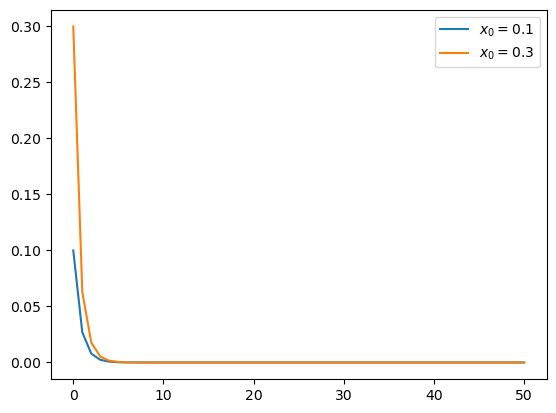

In [4]:
import matplotlib.pyplot as plt
import numpy as np
x_list = logistic_map(num_step=50,x=0.1, r=0.3)
plt.plot(x_list, label=f'$x_0={0.1}$')
x_list = logistic_map(num_step=50,x=0.3, r=0.3)
plt.plot(x_list, label=f'$x_0={0.3}$')
plt.legend()

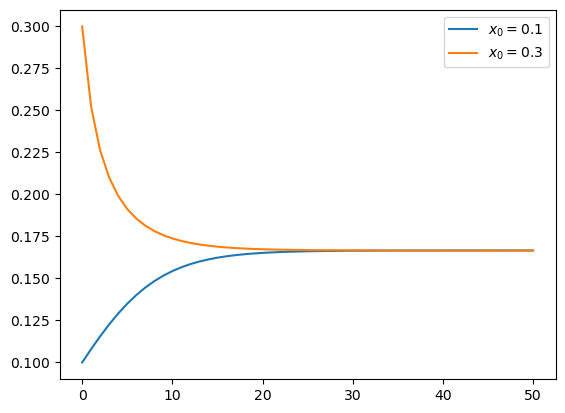

In [10]:
import matplotlib.pyplot as plt
import numpy as np
x_list = logistic_map(num_step=50,x=0.1, r=1.2)
plt.plot(x_list, label=f'$x_0={0.1}$')
x_list = logistic_map(num_step=50,x=0.3, r=1.2)
plt.plot(x_list, label=f'$x_0={0.3}$')
plt.legend()

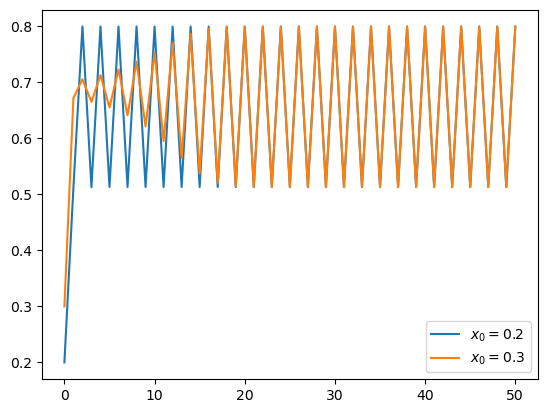

In [5]:
import matplotlib.pyplot as plt
import numpy as np
x_list = logistic_map(num_step=50,x=0.2, r=3.2)
plt.plot(x_list, label=f'$x_0={0.2}$')
x_list = logistic_map(num_step=50,x=0.3, r=3.2)
plt.plot(x_list, label=f'$x_0={0.3}$')
plt.legend()

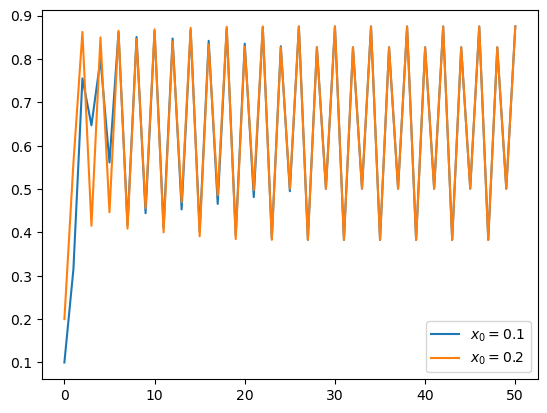

In [33]:
import matplotlib.pyplot as plt
import numpy as np
x_list = logistic_map(num_step=50,x=0.1, r=3.5)
plt.plot(x_list, label=f'$x_0={0.1}$')
x_list = logistic_map(num_step=50,x=0.2, r=3.5)
plt.plot(x_list, label=f'$x_0={0.2}$')
plt.legend()

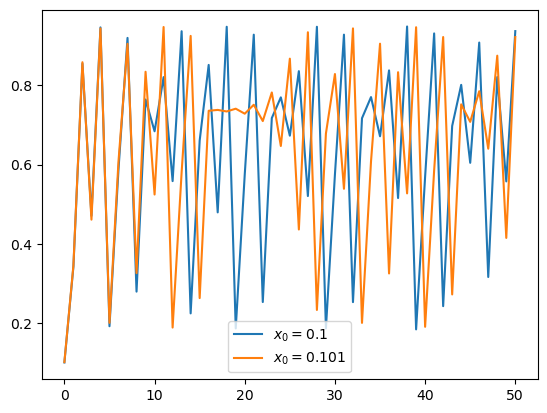

In [35]:
import matplotlib.pyplot as plt
import numpy as np
x_list = logistic_map(num_step=50,x=0.1, r=3.8)
plt.plot(x_list, label=f'$x_0={0.1}$')
x_list = logistic_map(num_step=50,x=0.101, r=3.8)
plt.plot(x_list, label=f'$x_0={0.101}$')
plt.legend()


$$
x_{n+1} =  r x _{n}(1-x_n)
$$


<img src='../gallery/logistic_map.gif' height=400 style='height:300px; background-color: white;'>

---

## Mysterious Transformation

\begin{align*}
&f_1: x_{n+1} = 0, \quad &&y_{n+1} = 0.16 y_n \quad &&&1\% 
\\
&f_2: x_{n + 1} = 0.85 x_n + 0.04 y_n, \quad &&y_{n + 1} = −0.04 x_n + 0.85 y_n + 1.6 \quad &&&85\%
\\
&f3: x_{n + 1} = 0.2 x_n − 0.26 y_n, \quad &&y_{n + 1} = 0.23 x_n + 0.22 y_n + 1.6 \quad &&&7\%
\\
&f4: x_{n + 1} = −0.15 x_n + 0.28 y_n, \quad &&y_{n + 1} = 0.26 x_n + 0.24 y_n + 0.44 \quad &&&7\%
\end{align*}

At each step, we apply $f_{1\sim 4}$ based on their probabilities, $p_1 = 1\%$, $p_2 = 85\%$, $p_3 = 7\%$ and $p_4 = 7\%$.

We can achieve this by __Monte Carlo__ method.

Draw a random number $r$ uniformly distributed between 0 and 1. 

`r = np.random.rand()`

- if $r < p_1 $, apply the first rule.
- if $ p_1 < r < p_1 + p_2 $, apply the second rule.
- if $ p_1 + p_2 < r < p_1 + p_2 + p_3 $, apply the third rule.
- if $p_1 + p_2 + p_3 < r  < 1$, apply the last rule.

<img src="../gallery/monte_carlo.png" alt="image" style="background-color: white;">


In [12]:
np.random.rand()

0.41383402684437276

In [2]:
def f(x,y,n):
    if n==1:
        x_new=0
        y_new=0.16*y
    if n==2:
        x_new=0.85*x+0.04*y
        y_new=-0.04*x + 0.85*y + 1.6
    if n==3:
        x_new=0.2*x - 0.26*y
        y_new=0.23*x + 0.22*y +1.6
    if n==4:
        x_new=-0.15*x + 0.28*y
        y_new=0.26*x + 0.24*y + 0.44
    return x_new, y_new

In [13]:
x=0
y=0
x_list=[x]
y_list=[y]
p1 = 0.01
p2 = 0.85
p3 = 0.07
p4 = 1 - p1 - p2 - p3
for i_step in range(100000):
    rd = np.random.rand()
    if rd<p1:
        x,y=f(x,y,1)
    elif rd<p1+p2:
        x,y=f(x,y,2)
    elif rd<p1+p2+p3:
        x,y=f(x,y,3)
    else:
        x,y=f(x,y,4)
    
    x_list.append(x)
    y_list.append(y)
    

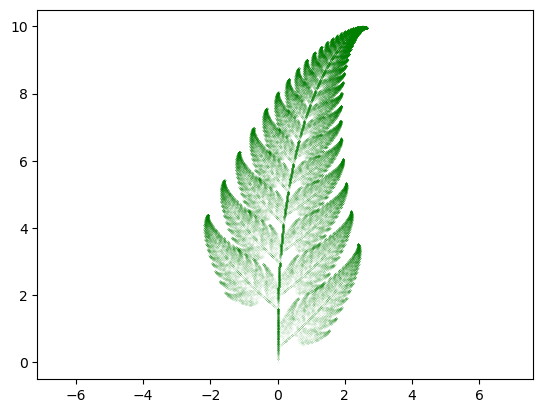

In [15]:
plt.plot(x_list,y_list,'.g',markersize=0.05)
plt.axis('equal')
fig = plt.gcf()
ax = plt.gca()
line = ax.get_lines()[0]

In [ ]:
def draw_frame(frame_index):
    frame_index = frame_index*500
    line.set_data(x_list[0:frame_index], y_list[0:frame_index])

In [17]:
import matplotlib.animation as animation
import IPython 
anim = animation.FuncAnimation(fig, draw_frame, frames=200, interval=20)
IPython.display.HTML(anim.to_jshtml())

---

## Chaos Game

https://en.wikipedia.org/wiki/Chaos_game

<img src="../gallery/chaos_game.png" alt="image" style="background-color: white;">

1. draw some points (vertices of a polygon).
2. pick a point in the polygon.
3. connect the point to a random vertex. The middle point of the line is the new point.
4. repeat step 3 `num_step` times.
5. visualize the points.


In [23]:
#generate a random integer number
np.random.randint(3)

2

In [17]:
def chaos_game_simple(num_step):
    v1=np.array([1,0])
    v2=np.array([-0.5,3**0.5/2])
    v3=np.array([-0.5,-3**0.5/2])
    r=np.array([0,0])
    x_list=[0]
    y_list=[0]
    
    for i_step in range(num_step):
        rd=np.random.randint(3)
        if rd==0:
            r = (r+v1)/2
        if rd==1:
            r = (r+v2)/2
        if rd==2:
            r = (r+v3)/2
        x_list.append(r[0])
        y_list.append(r[1])
    return x_list, y_list
        
    
    

(-0.574930583523721,
 1.0735422847809686,
 -0.9510867503444621,
 0.9520538445698254)

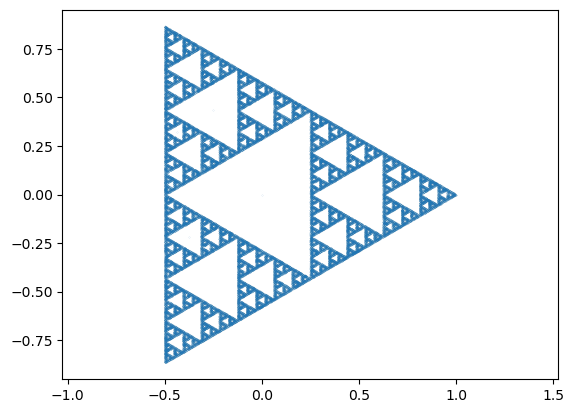

In [29]:
x_list,y_list = chaos_game_simple(100000)
plt.plot(x_list,y_list,'.', markersize=0.1)
plt.axis('equal')

This pattern is called __Sierpiński triangle__. 

In [30]:
def chaos_game(n_poly, p, num_step):
    theta=2*np.pi/n_poly
    angle=np.array(range(n_poly))*theta #angle for each vertex
    vertex=np.zeros((n_poly,2))
    vertex[:,0]=np.cos(angle)
    vertex[:,1]=np.sin(angle)
    r=np.array([0,0])
    x_list=[0]
    y_list=[0]
    
    for i_step in range(num_step):
        rd =np.random.randint(n_poly)
        r = p*r + (1-p)*vertex[rd,:]
        x_list.append(r[0])
        y_list.append(r[1])
    return x_list, y_list
    
    
    

(-1.0988492582989169,
 1.0993573687684943,
 -1.0998271936755386,
 1.0995308784237046)

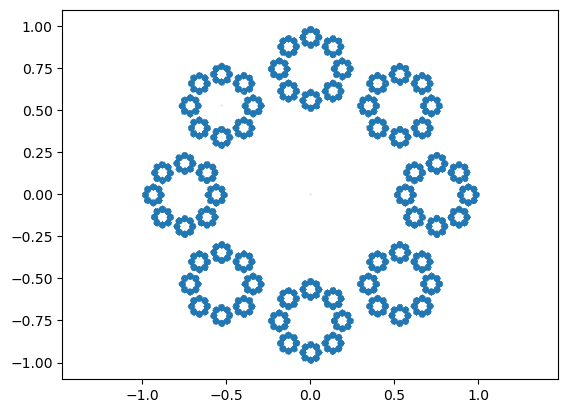

In [36]:
x_list,y_list = chaos_game(8,1/4,100000)
plt.plot(x_list,y_list,'.', markersize=0.2)
plt.axis('equal')

In [37]:
def chaos_game_upgraded(n_poly,p,num_step,center=False, edge=False, rstr_rule=False):
    '''
    an upgraded version to include the option to add midpoint of the edge or centers
    and the option to apply the restriction
    '''
    def restriction(rd):
        '''
        a function determines if rd is accepted
        '''
        if rd==rd_list[-1]: #rd_list is a list record all the past selections
            return False #not accepted
        else:
            return True #accepted
    
    vertex=np.zeros((n_poly,2))
    angle =np.array(range(n_poly))*2*np.pi/n_poly
    vertex[:,0]=np.cos(angle)
    vertex[:,1]=np.sin(angle)
    
    num_vertex=n_poly
    
    center_point=np.zeros((1,2))
    
    edge_point = (vertex + np.roll(vertex,1,axis=0))/2
    
    
    if center:
        vertex=np.vstack((vertex,center_point))
        num_vertex=num_vertex+1
    if edge:
        vertex=np.vstack((vertex,edge_point))
        num_vertex=num_vertex+n_poly
    
    r=np.array([0,0])
    x_list=[0]
    y_list=[0]
    rd_list=[-1] #a list record the history of selections,contains a negative number first,so the first step does not produce an error
    for i in range(num_step):
        rd = np.random.randint(num_vertex)
        if rstr_rule and restriction(rd)==False:
            continue
        else:
            rd_list.append(rd)
        r = p*r + (1-p)*vertex[rd]
        x_list.append(r[0])
        y_list.append(r[1])
    return x_list, y_list
        
        

In [98]:
x_list,y_list=chaos_game_upgraded(4,1/2,100000,center=False, edge=False,rstr_rule=True)

(-0.7333021887092626,
 0.7332865479324149,
 -0.7332301847258732,
 0.7332329313633444)

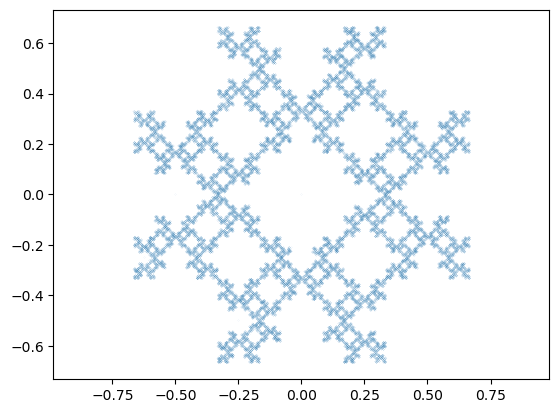

In [100]:
plt.plot(x_list,y_list,'.',markersize=0.05)
plt.axis('equal')

---

## cellular automaton

### elementary 1D cellular automaton

<img src='../gallery/cellular%20automaton.png' style='height:400px; background-color: white;' height=400/>

<table class="wikitable" style="text-align:center; margin:1em auto;">

<tbody><tr>
<th>current pattern</th>
<th>111</th>
<th>110</th>
<th>101</th>
<th>100</th>
<th>011</th>
<th>010</th>
<th>001</th>
<th>000
</th></tr>
<tr>
<th>new state for center cell
</th>
<td>0</td>
<td>1</td>
<td>0</td>
<td>1</td>
<td>1</td>
<td>0</td>
<td>1</td>
<td>0
</td></tr></tbody></table>

Put each generation together and we get a matrix of 0 and 1. The number rows equals the number of iterations and the number of columns equals the number of cells

<div style='font-size:20px'>What pattern does it form when we put all generations of cells together?</div>

In [8]:
import numpy as np
import matplotlib.pyplot as plt

In [114]:
def rule90(num_step, initial_array):
    num_cell = len(initial_array)
    m = np.zeros((num_step,num_cell),dtype=int) # a zero matrix num_step*num_cell, dtype specifies the data type, which is integer here.
    m[0,:]=initial_array # record the initial array
    
    for i in range(1, num_step):
        for i_cell in range(1,num_cell-1): #go through cell_1...cell_n-1
            if m[i-1,i_cell-1] == m[i-1,i_cell+1]:
                m[i,i_cell]=0
            else:
                m[i,i_cell]=1
    return m
    

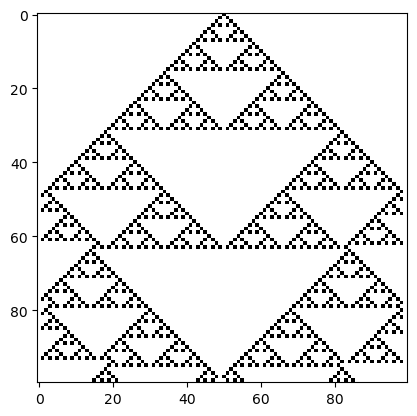

In [138]:
init_array = np.zeros(100)
init_array[50]=1 # initial condition
num_step =100
m = rule90(num_step, init_array)
plt.imshow(m, cmap='binary')

### Numbering the rules


__rule__ 90
<table class="wikitable" style="text-align:center; margin:1em auto;">

<tbody><tr>
<th>current pattern</th>
<th>111</th>
<th>110</th>
<th>101</th>
<th>100</th>
<th>011</th>
<th>010</th>
<th>001</th>
<th>000
</th></tr>
<tr>
<th>new state for center cell
</th>
<td>0</td>
<td>1</td>
<td>0</td>
<td>1</td>
<td>1</td>
<td>0</td>
<td>1</td>
<td>0
</td></tr></tbody></table>

It is called '90' because the '01011010' in binary in 90. For each configuration there are two possibilities (0 or 1), and therefore there are total $2^8=256$ rules.

Now let us write a function generate the elementary cellular automaton for general rules.

In [105]:
int('01011010',base=2)
np.binary_repr(90, 8)

'01011010'

In [132]:
def cellular_automaton(num_step, initial_array, rule):
    num_cell = len(initial_array)
    m = np.zeros((num_step,num_cell), dtype=int) # a zero matrix num_step*num_cell
    m[0,:]=initial_array # record the initial array
    rule = np.binary_repr(rule, 8)
    
    for i in range(1, num_step):
        for i_cell in range(1,num_cell-1): #go through cell_1...cell_n-1
            current_pattern = str(m[i-1, i_cell-1]) + str(m[i-1, i_cell]) + str(m[i-1, i_cell+1]) #get a string of current configuration, 110, etc
            current_pattern = int(current_pattern, base=2) #map to an integer from 0 to 7
            index = 7 - current_pattern #the position of the binary number rule
            m[i, i_cell] = rule[index]
    return m
    

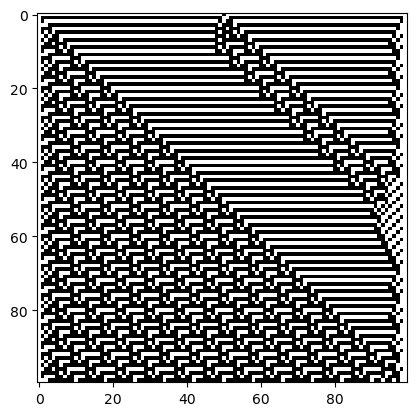

In [161]:
init_array = [0]*100
init_array[50] = 1
m = cellular_automaton(100, init_array, 107)
plt.imshow(m, cmap='binary')

### 2D Cellular Automaton

#### Conway's game of life

1. Any live cell with fewer than 2 live neighbors dies, as if by underpopulation.
2. Any live cell with 2 or 3 live neighbors lives on to the next generation.
3. Any live cell with more than 3 live neighbors dies, as if by overpopulation.
4. Any dead cell with exactly 3 live neighbors becomes a live cell, as if by reproduction.

<img src='https://upload.wikimedia.org/wikipedia/commons/e/e0/Game_of_life_glider_gun.svg' style="background-color: white;">


<img src='https://miro.medium.com/v2/resize:fit:640/format:webp/1*l4Lm4I87vDusPqCqs7l0yw.gif' style="background-color: white;">

## From cellular automaton to diffusion (heat) equation

Imagine turning on a heater in a freezing room. How does the heat diffuse through the room over time?

Let us first think about a 1D case, e.g., a metal rod being heated at the middle. We can model the rod as a series of discrete points. Each point exchanges heat with its two neighbors. The temperature at each point at the next time step can be calculated as the average of its own temperature and the temperatures of its two neighbors at the current time step. 

This setup is similar to the elementary cellular automaton, except that now the temperature of each cell can take continuous values instead of just 0 and 1.

Consider two neighboring points with temperatures $T_1$ and $T_2$, where $T_1 > T_2$. Heat will flow from the hotter point to the colder point. At the next step, the temperatures of $T_1$ will change to:
\begin{align*}
T_{1, new} &= T_1 - k (T_1 - T_2)
\end{align*}
where $k$ is a positive constant that determines the rate of heat transfer. Clearly, $T_1$ decreases if $T_1 > T_2$ and increases if $T_1 < T_2$. Similarly, the temperature of $T_2$ will change to:
\begin{align*}
T_{2,new} &= T_2 - k (T_1 - T_2)
\end{align*}

Now consider a 1D grid of $N$ points. The point at position $i$ has two neighbors at positions $i-1$ and $i+1$. The temperature at point $i$ at the next time step can be calculated as:
\begin{align*}
T_{i, new} &= T_i - k (T_i - T_{i-1}) - k (T_i - T_{i+1}) \\
\end{align*}
The points at the two ends only have one neighbor each. We can assume that the ends are insulated, meaning they do not exchange heat with the environment. Therefore, the temperature at the two ends will only change based on their single neighbor:
\begin{align*}
T_{0, new} &= T_0 - k (T_0 - T_1) \\
T_{N-1, new} &= T_{N-1} - k (T_{N-1} - T_{N-2}) \\
\end{align*}
This set of equations allows us to iteratively calculate the temperature distribution along the rod over time.

In [77]:
def diffusion(num_step, initial_array, k):
    N = len(initial_array)
    m = np.zeros((num_step, N))
    m[0,:]=initial_array
    for i in range(1,num_step):
        for j in range(1,N-1):
            m[i,j] = m[i-1,j] - k*(m[i-1,j]-m[i-1,j-1])- k*(m[i-1,j]-m[i-1,j+1])
        m[i,0] = m[i-1,0] - k*(m[i-1,0]-m[i-1,1])  #left boundary
        m[i,N-1] = m[i-1,N-1] - k*(m[i-1,N-1]-m[i-1,N-2])  #right boundary
    return m

In [145]:
def diffusion(num_step, initial_array, k):
    N = len(initial_array)
    m = np.zeros((num_step, N))
    m[0,:]=initial_array
    for i in range(1,num_step):
        m[i,1:N-1] = m[i-1,1:N-1] - k*(m[i-1,1:N-1]-m[i-1,0:N-2]) - k*(m[i-1,1:N-1]-m[i-1,2:N]) # vectorized version without inner loop; faster
        m[i,0] = m[i-1,0] - k*(m[i-1,0]-m[i-1,1])  #left boundary
        m[i,N-1] = m[i-1,N-1] - k*(m[i-1,N-1]-m[i-1,N-2])  #right boundary
    return m

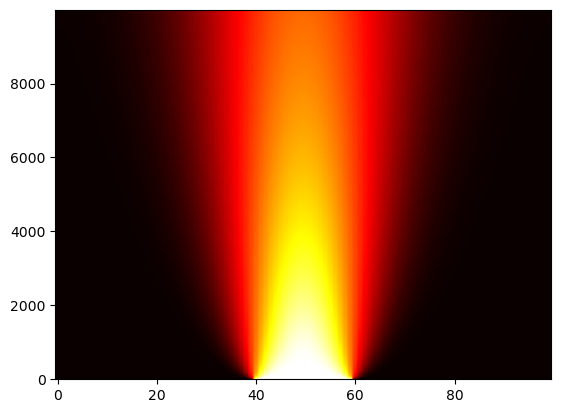

In [146]:
import numpy as np
import matplotlib.pyplot as plt
N = 100
initial_array = np.zeros(N)
initial_array[40:60]=100  #initial condition: a spike at the center
m = diffusion(10000, initial_array, 0.01)
plt.imshow(np.abs(m), cmap='hot', aspect='auto', origin='lower')

Now consider the case of continuous time and space. The temperature profile $T(x,t)$ is a function of both position $x$ and time $t$. From the discrete model, we have an iterative formula for the temperature at discrete points and time steps:
$$
T(x, t+\Delta t) = T(x,t) - k \left( T(x,t) - T(x-\Delta x, t) \right) - k \left( T(x,t) - T(x+\Delta x, t) \right)
$$

Now let us taylor expand $T(x \pm \Delta x, t)$ around $x$:
$$
T(x \pm \Delta x, t) = T(x,t) \pm \frac{\partial T}{\partial x} \Delta x + \frac{1}{2} \frac{\partial^2 T}{\partial x^2} (\Delta x)^2 + \cdots
$$
and taylor expand $T(x, t+\Delta t)$ around $t$:
$$
T(x, t+\Delta t) = T(x,t) + \frac{\partial T}{\partial t} \Delta t + \cdots
$$
Substituting these expansions into the iterative formula and keeping only the leading order terms, we obtain:
$$
\frac{\partial T}{\partial t} = \left (k \frac{\Delta x^2}{\Delta t} \right ) \frac{\partial^2 T}{\partial x^2}
$$
This is the diffusion equation (or heat equation) in one dimension, where the term in parentheses is the diffusion coefficient $D$:
$$
\frac{\partial T}{\partial t} = D \frac{\partial^2 T}{\partial x^2}
$$
Diffusion equation describes how heat diffuses through a medium over time. It shows that the rate of change of temperature at a point is proportional to the second spatial derivative of temperature, which represents the curvature of the temperature profile.

## Quantum particle in a box

Have you ever heard of the Schrödinger equation, which describes the behavior of quantum particles? In one dimension, it is given by:
$$
i \hbar \frac{\partial \psi}{\partial t} = -\frac{\hbar^2}{2m} \frac{\partial^2 \psi}{\partial x^2} + V(x) \psi
$$
Here, $\psi(x,t)$ is the wavefunction of the particle, $\hbar$ is the reduced Planck constant, $m$ is the mass of the particle, and $V(x)$ is the potential energy as a function of position. You don't need to understand what the wavefunction is for now; just think of it as a mathematical function that contains information about the particle's state, and the important thing is that it can take __complex values__.

Now let's move the $i \hbar$ to the right side:
$$
\frac{\partial \psi}{\partial t} = \frac{i \hbar}{2m} \frac{\partial^2 \psi}{\partial x^2} - \frac{i}{\hbar} V(x) \psi
$$

Let's further think about a free particle, where the potential $V(x) = 0$. The equation simplifies to:
$$
\frac{\partial \psi}{\partial t} = \frac{i \hbar}{2m} \frac{\partial^2 \psi}{\partial x^2}
$$
Hmm, wait a second. This looks very similar to the diffusion equation we just discussed, except for the factor of $i$ in front of the right-hand side. This means that the time evolution of a quantum particle's wavefunction is similar to diffusion, but with a twist due to the complex nature of the wavefunction.

In [185]:
def schrodinger(num_step, initial_array, k): # k is a imaginary number now for schrodinger equation
    N = len(initial_array)
    m = np.zeros((num_step, N), dtype=complex) #make m a complex matrix
    m[0,:]=initial_array
    for i in range(1,num_step):
        m[i,1:N-1] = m[i-1,1:N-1] - k*(m[i-1,1:N-1]-m[i-1,0:N-2]) - k*(m[i-1,1:N-1]-m[i-1,2:N]) # vectorized version without inner loop; faster
        m[i,0] = m[i-1,0] - k*(m[i-1,0]-m[i-1,1])  #left boundary
        m[i,N-1] = m[i-1,N-1] - k*(m[i-1,N-1]-m[i-1,N-2])  #right boundary
    return m

### a localized particle
Let's first consider a localized particle in a 1D box. We can model the initial wavefunction as a spike at the center of the box. Over time, the wavefunction will spread out, demonstrating the uncertainty principle and the wave-like nature of quantum particles.

In this case, we know for certain the location of the particle at the beginning. As a result, we have maximum uncertainty in its momentum, leading to a rapid spread of the wavefunction over time.

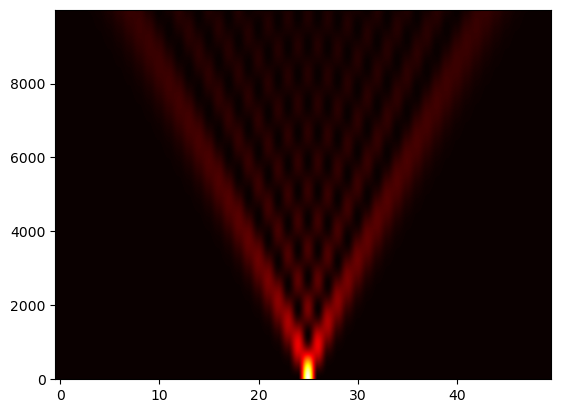

In [189]:
import numpy as np
import matplotlib.pyplot as plt
N = 50
initial_array = np.zeros(N)
initial_array[25]=1  # a localized particle in the center
m = schrodinger(10000, initial_array, 0.001j) #note the imaginary unit j
plt.imshow(np.abs(m)**2, cmap='hot', aspect='auto', origin='lower')

### a stationary wavepacket

Now let's consider a wavepacket, which is less localized than a spike but still concentrated in a certain region. A wavepacket can be modeled using a Gaussian function:

$$
\psi(x,0) = A e^{-\frac{x^2}{2\sigma^2}}
$$
where $\sigma$ determines the width of the wavepacket. When $\sigma$ is small, the wavepacket is more localized in space, leading to greater uncertainty in momentum and faster spreading over time. Conversely, a larger $\sigma$ results in a less localized wavepacket with slower spreading.

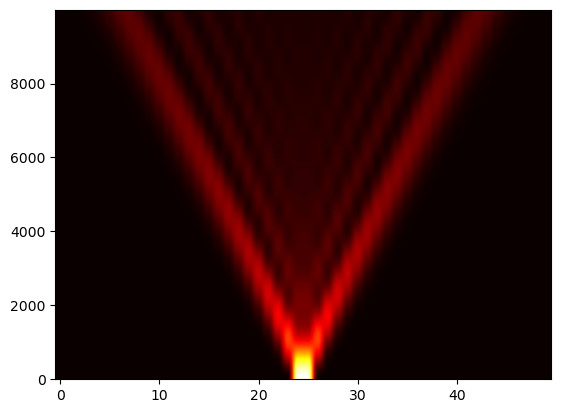

In [190]:
import numpy as np
import matplotlib.pyplot as plt
N = 50
initial_array = np.zeros(N)
x = np.linspace(-N/2,N/2,N)
sigma = 0.1
initial_array = np.exp(-x**2/sigma)  #initial condition: a spike at the center
m = schrodinger(10000, initial_array, 0.001j) #note the imaginary unit j
plt.imshow(np.abs(m)**2, cmap='hot', aspect='auto', origin='lower')

### a moving particle
Now let's consider a moving particle. We can model the initial wavefunction as a Gaussian wavepacket multiplied by a complex exponential factor that represents momentum:
$$
\psi(x,0) = A e^{-\frac{x^2}{2\sigma^2}} e^{i k x}
$$

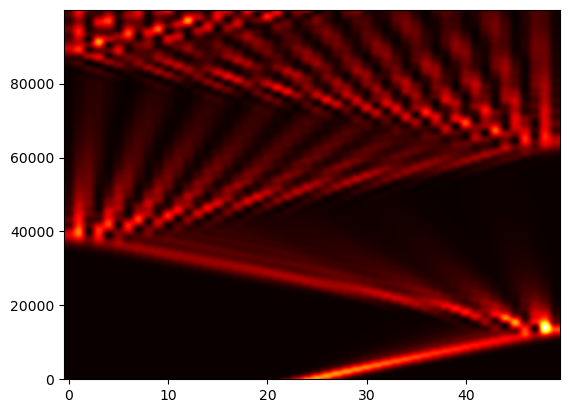

In [191]:
import numpy as np
import matplotlib.pyplot as plt
N = 50
initial_array = np.zeros(N)
x = np.linspace(-N/2,N/2,N)
sigma = 10
k =2
initial_array = np.exp(-x**2/sigma + 1j*k*x)  #initial condition: a spike at the center
m = schrodinger(100000, initial_array, 0.001j) #note the imaginary unit j
plt.imshow(np.abs(m)**2, cmap='hot', aspect='auto', origin='lower')

## An Oscillating Wavepacket

Now let's add the potential term back into the Schrödinger equation. The potential term introduces oscillations in the wavefunction, leading to more complex dynamics.

$$
\frac{\partial \psi}{\partial t} = \frac{i \hbar}{2m} \frac{\partial^2 \psi}{\partial x^2} - \frac{i}{\hbar} V(x) \psi
$$

Let's consider a simple harmonic oscillator potential:
$$
V(x) = \frac{1}{2} m \omega^2 x^2
$$
and see how it affects the evolution of the wavepacket.


In [217]:
def schrodinger(num_step, initial_array, k, omega): # k is a imaginary number now for schrodinger equation, omega represents the strength of the potential
    N = len(initial_array)
    m = np.zeros((num_step, N), dtype=complex) #make m a complex matrix
    m[0,:]=initial_array
    x = np.linspace(-N/2,N/2,N)
    for i in range(1,num_step):
        m[i,1:N-1] = m[i-1,1:N-1] - k*(m[i-1,1:N-1]-m[i-1,0:N-2]) - k*(m[i-1,1:N-1]-m[i-1,2:N]) # vectorized version without inner loop; faster
        m[i,0] = m[i-1,0] - k*(m[i-1,0]-m[i-1,1])  #left boundary
        m[i,N-1] = m[i-1,N-1] - k*(m[i-1,N-1]-m[i-1,N-2])  #right boundary
        m[i,:] = m[i,:] - 1j*omega**2*m[i-1,:]*x**2  # potential term
    return m

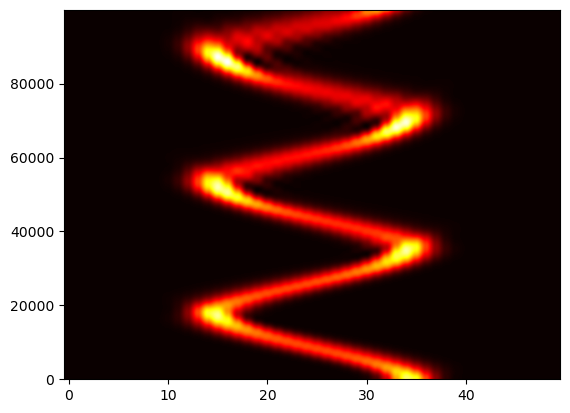

In [221]:
import numpy as np
import matplotlib.pyplot as plt
N = 50
initial_array = np.zeros(N)
x = np.linspace(-N/2,N/2,N)
sigma = 10
k =0
initial_array = np.exp(-(x-10)**2/sigma + 1j*k*x)  #initial condition: a spike at the center
m = schrodinger(100000, initial_array, 0.001j, 0.003) #note the imaginary unit j
plt.imshow(np.abs(m)**2, cmap='hot', aspect='auto', origin='lower')